# Coupling of absorption and scattering (2/3): water vapour retrieval

hGRS retrieves the water vapour column $W$ on each mega-pixel (20 x 20 pixels) by fitting the TOA reflectance of the
water pixels between 800 and 1300 nm. Two models are compared here:

* **decoupled** (hGRS 1.2.0, `gas_coupling: decoupled`): the whole signal has the direct-beam transmittance,
  $R(\lambda) = T_{wv}(\lambda; W, \bar M)\,(a\lambda + b)$;
* **coupled** (`gas_coupling: path_length`, `hgrs.gas_coupling`): the path reflectance $R_p$ (shape of the TOA LUT
  at the first-guess AOT, free amplitude $k$) has the transmittance of the photon path-length model, the rest the
  direct-beam one: $R(\lambda) = T_{atm}(\lambda; W)\, k\, R_p(\lambda) + T_{wv}(\lambda; W)\,(a\lambda + b)$.

Notebook 1 showed that over black water a decoupled model sees 20-42 % of the water vapour column at 941 nm. Here:

1. retrieval test on the SOS-ABS simulations (known water vapour column);
2. the EnMAP test scene (Lucinda, 2026-05-31): TCWV of hGRS against CAMS, radiometry of the water spectrum, fits;
3. products of the coupled processing on two EnMAP scenes.

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import coupling_tools as ct
from hgrs.gas_coupling import GasTransmittance

warnings.filterwarnings('ignore')
ct.set_style()
pd.set_option('display.precision', 3)

sos_abs, sos_noabs, tgdir_abs, tgdir_noabs = ct.load_sos()
bands = ct.Bands.enmap_lucinda()
gas = ct.gas_lut()
gt = GasTransmittance(gas, coef_abs_scat=0.35)          # hgrs.gas_coupling, as in the processing
VZA, AZI = 15.9, 90.
WIN = np.concatenate([c for k, c in bands.in_windows().items() if k in ('H2O-820', 'H2O-940')])
LAM = WIN / 1000
print('bands of the fit (inside the SOS-ABS windows):', np.round(WIN, 1))

bands of the fit (inside the SOS-ABS windows): [816.6 824.4 931.2 941.2 951.4 961.6 972. ]


## 1. Retrieval on SOS-ABS simulations

The TOA reflectance of the simulations (water vapour column $U$ = 0.5, 2, 4 g cm$^{-2}$; AOT 0.05-0.4; $\theta_s$ =
20-70°; water albedo 0, 0.03, 0.1) is averaged in the EnMAP bands of the 808-836 and 890-990 nm windows (EnMAP has no
band between 888 and 931 nm on this product) and fitted with:

* **decoupled**: the hGRS model with the REPTRAN transmittance of hGRS;
* **decoupled, SOS database**: the same model with the SOS-ABS direct-beam transmittance (`ct.DirectBeam`), to
  separate the REPTRAN-CKD difference from the coupling;
* **coupled**: the model of `hgrs.gas_coupling` as in the processing, $R_p$ the path reflectance of the simulation
  without absorption (black water, same AOT), amplitude $k$ free;
* **coupled, known path** ($k$ = 1): upper bound of the gain when the path reflectance is known.

In [2]:
direct_beam = ct.DirectBeam(tgdir_abs, tgdir_noabs, bands, WIN)
grid = np.array([0, 1, 2, 5, 7.5, 10, 12.5, 15, 20, 25, 30, 35, 40, 45, 50, 60, 80.])

def tables(m, aot):
    td = np.array([bands.average(gt.water_vapor('dir', m, w), gas.wl.values, WIN) for w in grid])
    ta = np.array([bands.average(gt.water_vapor('atm', m, w, aot), gas.wl.values, WIN) for w in grid])
    return td, ta

interp = lambda tab, w: np.array([np.interp(w, grid, tab[:, i]) for i in range(tab.shape[1])])

def fit(model, x0, lo, hi, y):
    return least_squares(lambda p: model(p) - y, x0, bounds=(lo, hi)).x

rows = []
for sza in (20., 40., 55., 70.):
    m = ct.air_mass(sza, VZA)
    for aot in (0.05, 0.15, 0.4):
        td, ta = tables(m, aot)
        path = bands.convolve_windows(ct.toa(sos_noabs, sza, VZA, AZI, albedo=0., aot_ref=aot)).sel(wl=WIN).values
        for U in (0.5, 2., 4.):
            for alb in (0., 0.03, 0.1):
                y = bands.convolve_windows(ct.toa(sos_abs.sel(h2o=U), sza, VZA, AZI, albedo=alb, aot_ref=aot)).sel(wl=WIN).values
                lin = lambda p: p[-2] * LAM + p[-1]
                r = dict(sza=sza, aot=aot, U=U, albedo=alb)
                r['decoupled'] = fit(lambda p: interp(td, p[0]) * lin(p), [20, 0, y.max()], [0, -10, -1], [80, 10, 1], y)[0]
                r['decoupled, SOS db'] = fit(lambda p: direct_beam(m * p[0] / 10) * lin(p), [20, 0, y.max()],
                                             [0, -10, -1], [80, 10, 1], y)[0]
                r['coupled'] = fit(lambda p: interp(ta, p[0]) * p[1] * path + interp(td, p[0]) * lin(p),
                                   [20, 1, 0, 0], [0, 0, -10, -1], [80, 5, 10, 1], y)[0]
                r['coupled, known path'] = fit(lambda p: interp(ta, p[0]) * path + interp(td, p[0]) * lin(p),
                                               [20, 0, 0], [0, -10, -1], [80, 10, 1], y)[0]
                rows.append(r)
res = pd.DataFrame(rows)
MODELS = ['decoupled', 'decoupled, SOS db', 'coupled', 'coupled, known path']
for k in MODELS:
    res[k] = res[k] / (10 * res.U)            # retrieved / true column
ok = res.sza > 20                               # theta_s = 20 deg: sun glint in the black-water signal (see notebook 1)
res[ok].groupby('albedo')[MODELS].median().rename_axis('albedo (theta_s 40-70 deg): median W_ret / U')

,decoupled,"decoupled, SOS db",coupled,"coupled, known path"
albedo (theta_s 40-70 deg): median W_ret / U,,,,
0.00,0.251,0.285,0.456,0.965
0.03,0.552,0.595,0.819,0.955
0.10,0.754,0.783,0.877,0.951


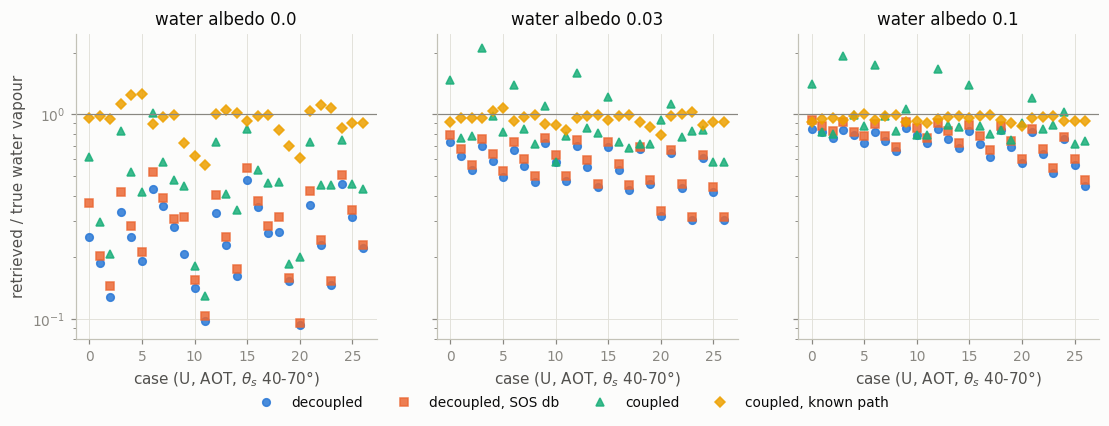

p10-p90 of W_ret / U, theta_s 40-70 deg:


decoupled       decoupled, SOS db       coupled        \
             0.1   0.9               0.1   0.9     0.1   0.9   
albedo                                                         
0.00        0.14  0.39              0.15  0.46    0.19  0.78   
0.03        0.38  0.70              0.40  0.75    0.64  1.42   
0.10        0.57  0.84              0.60  0.91    0.77  1.51   

       coupled, known path        
                       0.1   0.9  
albedo                            
0.00                  0.67  1.11  
0.03                  0.87  1.01  
0.10                  0.91  0.98

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, alb in zip(axes, (0., 0.03, 0.1)):
    d = res[ok & (res.albedo == alb)]
    for i, k in enumerate(MODELS):
        ax.plot(np.arange(len(d)), d[k].values, linestyle='none', marker=ct.MARKERS[i], color=ct.COLORS[i], ms=5,
                label=k, alpha=0.85)
    ax.axhline(1, color=ct.MUTED, lw=0.8)
    ax.set_title(f'water albedo {alb}')
    ax.set_xlabel('case (U, AOT, $\\theta_s$ 40-70°)')
    ax.set_yscale('log')
axes[0].set_ylabel('retrieved / true water vapour')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.1))
plt.show()
print('p10-p90 of W_ret / U, theta_s 40-70 deg:')
res[ok].groupby('albedo')[MODELS].quantile([.1, .9]).unstack().round(2)

For $\theta_s$ = 40-70° (out of the sun glint at this viewing geometry):

* the **decoupled** model underestimates the water vapour the more, the darker the water; the REPTRAN-CKD database
  difference explains only a small part of it (decoupled with the SOS database);
  (median 25 % of the true column over black water, 14-39 % from the 10th to the 90th percentile);
* the **coupled** model of hGRS, with the shape of the path reflectance and a free amplitude $k$, improves the
  retrieval (median 46 % over black water, 82 % and 88 % for water albedos of 0.03 and 0.1) but still
  underestimates it over dark water: the amplitude $k$ and the column $W$ partly compensate each other;
* with the path reflectance known ($k$ = 1), the coupled model is within 5 % in median (95-97 %) for all albedos.

The coupled retrieval therefore needs a constraint on the path reflectance (from the aerosol retrieval or the TOA LUT
at the right AOT) to reach its potential. The remaining errors are largest for the cleanest atmospheres (AOT 0.05),
where the path reflectance is Rayleigh scattering high above the water vapour.

## 2. EnMAP test scene (Lucinda, 2026-05-31)

Clear, dark coastal water off Queensland; CAMS: TCWV 11.0 kg m$^{-2}$, AOD(550) 0.041 at the scene centre.

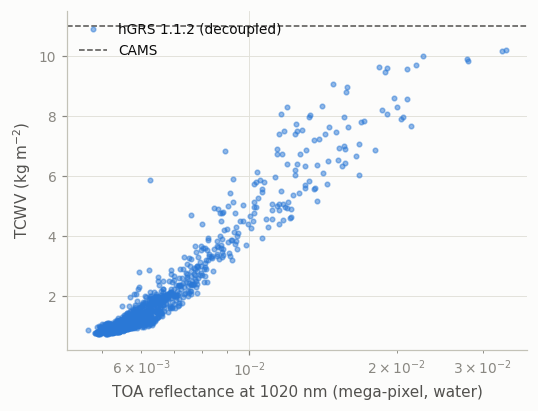

median TCWV of hGRS over water: 1.00 kg m-2 (CAMS 11.0); correlation with log brightness 0.97


In [4]:
L1 = os.environ.get('HGRS_TEST_L1', '/data/satellite/enmap/EnMAP_L1C/L1C_sep2026/Lucinda/'
                    'ENMAP01-____L1C-DT0000195771_20260531T005713Z_003_V010506_20260602T201336Z')
L2_V112 = glob.glob(os.path.join(os.environ.get('HGRS_TEST_L2', '/data/satellite/enmap/L2A/L1C_sep2026/Lucinda'), '*V1.1.2.nc'))[0]
TCWV_CAMS = 11.0
from hgrs.drivers.enmap import EnmapDriver
driver = EnmapDriver()
l1 = driver.read(L1)
l2 = xr.open_dataset(L2_V112)
water = l2.Rrs.isel(wl=0).transpose('y', 'x').notnull()
ny, nx = l2.sizes['yc'], l2.sizes['xc']

def coarse(da):
    """mean of the water pixels of each mega-pixel (as hGRS), array (wl, yc, xc)"""
    v = da.where(water).transpose('wl', 'y', 'x').values
    P = np.full((v.shape[0], ny * 20, nx * 20), np.nan)
    P[:, :v.shape[1], :v.shape[2]] = v
    return np.nanmean(P.reshape(v.shape[0], ny, 20, nx, 20), axis=(2, 4))

r1020 = coarse(l1.Rtoa.sel(wl=[1020], method='nearest'))[0]
t = l2.tcwv.transpose('yc', 'xc').values
okc = np.isfinite(t) & np.isfinite(r1020)
fig, ax = plt.subplots(figsize=(5.4, 4))
ax.plot(r1020[okc], t[okc], linestyle='none', marker='o', ms=3, alpha=0.5, color=ct.COLORS[0], label='hGRS 1.1.2 (decoupled)')
ax.axhline(TCWV_CAMS, color=ct.INK2, linestyle='--', lw=1, label='CAMS')
ax.set_xscale('log'); ax.set_xlabel('TOA reflectance at 1020 nm (mega-pixel, water)'); ax.set_ylabel('TCWV (kg m$^{-2}$)')
ax.legend(loc='upper left'); plt.show()
print(f'median TCWV of hGRS over water: {np.median(t[okc]):.2f} kg m-2 (CAMS {TCWV_CAMS});'
      f' correlation with log brightness {np.corrcoef(np.log(r1020[okc]), t[okc])[0, 1]:.2f}')

The TCWV retrieved over water is about 1 kg m$^{-2}$ against 11 kg m$^{-2}$ for CAMS, and it rises with the
brightness of the mega-pixel (glint, land fraction): the signature of the decoupling. The unit of the product
(kg m$^{-2}$) is that of the LUTs and of the retrieval; the values are not a unit error.

Using the CAMS column instead of the retrieval over dark water was tried with the **decoupled** correction
(full scene, 2026-11-12): the residual water vapour features of $R_{rs}$ over dark water, measured by the band depth
(band minus the mean of its neighbours), went from -3.1e-4 / -5.0e-5 / +6.9e-4 sr$^{-1}$ (720 / 816 / 941 nm) to
+6.2e-4 / +5.4e-4 / +2.8e-3 sr$^{-1}$: a correction with the true column and the direct-beam transmittance for the
whole signal over-corrects. The low retrieved column is an *effective* column, consistent with the decoupled
correction, not a physical one. The coupled processing needs both the coupled retrieval and the coupled correction.

### Radiometry of the water spectrum

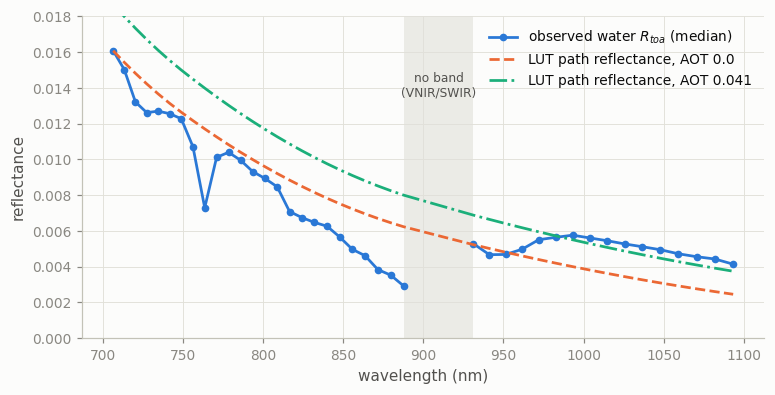

In [5]:
from hgrs.config import get_app_config
lut = xr.open_dataset(get_app_config().resolve_lut('toa'))     # TOA LUT of the hGRS configuration
lut = lut.isel(wind=1).sel(model='COAV_rh70')
lut['wl'] = lut.wl * 1000
sza, vza, raa = float(l1.sza.mean()), float(l1.vza.mean()), float(l1.raa.mean())
I = lut.I.interp(vza=vza, azi=(180 - raa) % 360).interp(sza=sza, method='quadratic').squeeze()
spec = l1.Rtoa.where(water).sel(wl=slice(700, 1100)).median(['x', 'y'])
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, part in enumerate((spec.sel(wl=slice(None, 900)), spec.sel(wl=slice(900, None)))):   # VNIR, SWIR
    ax.plot(part.wl, part, **ct.series(0), ms=4, label='observed water $R_{toa}$ (median)' if k == 0 else None)
for i, a in enumerate((0., 0.041)):
    r = (I.interp(aot_ref=a).interp(wl=spec.wl.values, method='quadratic') / np.cos(np.radians(sza)))
    ax.plot(spec.wl, r, color=ct.COLORS[i + 1], linestyle=ct.STYLES[i + 1], label=f'LUT path reflectance, AOT {a}')
ax.axvspan(888, 931, color=ct.GRID, alpha=0.6, lw=0)
ax.text(909.5, 0.0135, 'no band\n(VNIR/SWIR)', ha='center', fontsize=8, color=ct.INK2)
ax.set_xlabel('wavelength (nm)'); ax.set_ylabel('reflectance'); ax.set_ylim(0, 0.018)
ax.legend(loc='upper right'); plt.show()

Over this very dark water the observed spectrum is not consistent with any path reflectance: at the red end of the
VNIR detector (840-888 nm) it falls well below the Rayleigh-only reflectance (0.0029 at 888 nm), and the SWIR detector
(931-1060 nm) starts above it, with a shallow 940 nm band. The LUT spectral grid is coarse (nodes at 800 and 1000 nm),
but not enough to explain this. A low-signal radiometric offset of the two detectors (stray light, dark signal) is a
likely cause, to be checked with the EnMAP L1 documentation and other dark scenes.

### Fits on the mega-pixels

In [6]:
sub = l1.Rtoa.sel(wl=slice(795, 1305))
WL = sub.wl.values
Rc = coarse(sub)
npix = np.isfinite(coarse(l1.Rtoa.sel(wl=[1020], method='nearest'))[0])
m = ct.air_mass(sza, vza)
conv = lambda tab: driver.sensor_description.convolve(tab).rename({'wl_sensor': 'wl'}).sel(wl=WL, method='nearest').transpose('tcwv', 'wl').values
g2 = np.array([0, 1, 2, 5, 7.5, 10, 12.5, 15, 20, 25, 30, 35, 40, 45, 50, 60.])
TD = conv(gt.water_vapor_table('dir', m, g2)); TA = conv(gt.water_vapor_table('atm', m, g2, 0.041))
PATH = (I.interp(aot_ref=0.041).interp(wl=WL, method='quadratic') / np.cos(np.radians(sza))).values
lam = WL / 1000
it = lambda tab, w: np.array([np.interp(w, g2, tab[:, i]) for i in range(tab.shape[1])])
cells = np.argwhere(np.isfinite(Rc).all(0) & np.isfinite(t))
cells = cells[np.random.default_rng(0).choice(len(cells), min(120, len(cells)), replace=False)]
models = {
    'decoupled': (lambda p: it(TD, p[0]) * (p[1] * lam + p[2]), [11, 0, .01], [0, -10, -1], [60, 10, 1]),
    'coupled (hGRS)': (lambda p: it(TA, p[0]) * p[1] * PATH + it(TD, p[0]) * (p[2] * lam + p[3]), [11, 1, 0, 0], [0, 0, -10, -1], [60, 5, 10, 1]),
    'coupled + additive offset': (lambda p: it(TA, p[0]) * p[1] * PATH + it(TD, p[0]) * (p[2] * lam + p[3]) + p[4],
                                  [11, 1, 0, 0, 0], [0, 0, -10, -1, -.02], [60, 5, 10, 1, .02]),
}
rows = []
for band_set, mask in [('800-1300 nm', np.ones(WL.size, bool)), ('SWIR only, 931-1300 nm', WL > 900)]:
    for name, (f, x0, lo, hi) in models.items():
        w = [least_squares(lambda p: (f(p) - Rc[:, j, i])[mask], x0, bounds=(lo, hi)).x[0] for j, i in cells]
        rows.append({'bands': band_set, 'model': name, 'TCWV median': np.median(w),
                     'p10': np.percentile(w, 10), 'p90': np.percentile(w, 90)})
pd.DataFrame(rows).set_index(['bands', 'model']).rename_axis(columns=f'kg m-2 (CAMS {TCWV_CAMS})')

kg m-2 (CAMS 11.0)                                TCWV median     p10     p90
bands                  model                                                 
800-1300 nm            decoupled                        0.934   0.758   3.779
                       coupled (hGRS)                   0.980   0.787   4.438
                       coupled + additive offset        0.283   0.139   3.145
SWIR only, 931-1300 nm decoupled                        1.637   1.326   4.699
                       coupled (hGRS)                   3.570   3.081   6.726
                       coupled + additive offset       22.018  13.689  24.475

With all the bands of 800-1300 nm, the coupled model hardly changes the retrieved column on this scene: the VNIR
bands below the Rayleigh reflectance drive the fit (the amplitude of the path reflectance drops to about 0.4).
With the SWIR bands only, the coupled model retrieves about twice as much water vapour as the decoupled one on the
same bands (3.6 against 1.6 kg m$^{-2}$), still far from CAMS. A free additive offset is not a solution as such: it
makes the fit unstable (0.3 kg m$^{-2}$ with all the bands, 22 kg m$^{-2}$ with the SWIR bands). On this scene the
radiometry of the dark-water spectrum limits any retrieval.

## 3. Coupled processing: products

Full scenes processed with `hgrs_enmap` in both modes (`gas_coupling: decoupled, o2_model: reptran` and the default
`path_length, lbl`). The decoupled run reproduces hGRS 1.2.0 exactly (all variables identical).

In [7]:
# metrics of the products (coupling_products.py, run on the L2A files of both modes)
prod = pd.read_csv('coupling_products_metrics.csv').set_index(['scene', 'mode'])
depth_cols = [c for c in prod.columns if c.startswith('depth')]
prod[['tcwv', 'aot_ref'] + depth_cols].style.format('{:.2e}', subset=depth_cols).format('{:.3g}', subset=['tcwv', 'aot_ref'])

*Band depth*: median of $R_{rs}$(band) minus the linear continuum of its neighbours (sr$^{-1}$), 0 when the
absorption feature is removed; TCWV in kg m$^{-2}$ (CAMS: 11.0 for Lucinda, 14.1 for Brasil). The O2 bands are
discussed in notebook 3.

On both scenes the coupled processing reduces the residual of the 941 nm band (+6.7e-4 to +4.7e-4 and +8.2e-4 to
+4.8e-4 sr$^{-1}$) and increases the TCWV a little (0.98 to 1.06, 2.58 to 3.13 kg m$^{-2}$), but the residuals of
the 720 and 817 nm bands become more negative. On both scenes the AOT of the retrieval is at its lower bound
(0.002): the path reflectance of the TOA LUT is above the dark-water signal in the near infrared (section 2), and the
coupled correction multiplies it by $T_{atm}/T_d > 1$ in the absorption bands, which deepens the negative residuals.
The coupling is not the cause of this excess of path reflectance, but it makes it visible.

## Summary and options

* The decoupled retrieval measures an **effective** column that depends on the share of the path reflectance:
  over black water it is 15-40 % of the true column (SOS-ABS), about 10 % on the Lucinda scene and 20 % on the
  Brasil scene (against CAMS). It is consistent with
  the decoupled correction, but it is not a water vapour product.
* hGRS now has the coupled model (`gas_coupling: path_length`): path-length transmittance of `radcalnet_oc` for the path
  reflectance, direct beam for the surface terms, in the retrieval and in the correction. On simulations it retrieves
  46-88 % of the column in median with a free path amplitude, 95-97 % with the path reflectance known.
* On the two dark EnMAP scenes the gain is limited by the path reflectance (AOT at its lower bound, path reflectance
  of the LUT above the signal) and by the radiometry of the dark-water spectrum (VNIR/SWIR inconsistency); with the
  SWIR bands only, the coupled retrieval gives twice as much water vapour as the decoupled one.

Options for the next steps:

1. retrieve the water vapour on the SWIR bands only for EnMAP (configurable fit range per sensor), or with a detector
   offset term;
2. constrain the path amplitude $k$ with the aerosol retrieval (iterate water vapour / aerosol once), and
   investigate why the AOT stays at its lower bound on dark water (path reflectance of the TOA LUT, its spectral
   grid with nodes at 800 and 1000 nm, calibration);
3. extend the coupling coefficients to the 1130 nm band (SOS-ABS set v3, being computed in `radcalnet_oc`);
4. use CAMS as the prior of the retrieval (regularised fit) where the water vapour signal is weak.